# Odometry Exercise 3 — 有效轮距 B（原地转圈标定）

**机器人**：Pololu 3Pi+ 32U4 + M5Stack StampC3，程序 `ex3_rotation/Rotate/Rotate.ino`（编码器闭环原地转，左右计数之和保持 0）。

**方法**：里程计用 Ex2 标定的轮半径 r = 16.36 mm 和旧轮距 B_old = 90 mm 计算转角 Δθ_est；
在测试纸的放射标记上量实际转角 Δθ_actual。因为 Δθ = (s_R − s_L) / B，估计角与 B 成反比：

$$B_{new} = B_{old}\,\frac{\Delta\theta_{est}}{\Delta\theta_{actual}}$$

- 标定组：±90°、±180° → 用最小二乘（过原点）拟合斜率 k = Σ(a·e)/Σa²，B = B_old · k
- 留作检验：±270°（不参与拟合），比较修正前后的航向误差
- 符号：+ = 逆时针（与里程计 θ 一致）

In [1]:
import os, math, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from a clone of the repo, or in Colab (clones it first).
REPO_URL = "https://github.com/comradeofjustice/Bristol_odometry"
if os.path.isdir("ex3_rotation"):
    BASE = "ex3_rotation"
elif os.path.isdir("../data") and os.path.isfile("../measurements.csv"):
    BASE = ".."
else:
    if not os.path.isdir("Bristol_odometry"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    BASE = "Bristol_odometry/ex3_rotation"

WHEEL_RADIUS_MM = 16.36     # Exercise 2 result, shared by both wheels
B_OLD_MM = 90.0             # separation used by the odometry during acquisition
ENCODER_CPR = 358.3
MM_PER_COUNT = 2 * math.pi * WHEEL_RADIUS_MM / ENCODER_CPR
print(f"data folder: {BASE}/data   r = {WHEEL_RADIUS_MM} mm, B_old = {B_OLD_MM} mm, "
      f"{MM_PER_COUNT:.4f} mm/count")

data folder: Bristol_odometry/ex3_rotation/data   r = 16.36 mm, B_old = 90.0 mm, 0.2869 mm/count


## 1. 读取测量表和日志，用里程计模型重放每次试验

In [2]:
meas = pd.read_csv(f"{BASE}/measurements.csv")


def replay_odometry(left, right, separation_mm):
    # Same Euler update as OdometryModel.cpp: x, y, theta from encoder increments.
    x = y = th = 0.0
    xs, ys, ts = [0.0], [0.0], [0.0]
    for i in range(1, len(left)):
        sl = (left[i] - left[i - 1]) * MM_PER_COUNT
        sr = (right[i] - right[i - 1]) * MM_PER_COUNT
        ds = 0.5 * (sl + sr)
        x += ds * math.cos(th)
        y += ds * math.sin(th)
        th += (sr - sl) / separation_mm
        xs.append(x); ys.append(y); ts.append(th)
    return np.array(xs), np.array(ys), np.array(ts)


rows = []
logs = {}
for i, m in meas.iterrows():
    d = pd.read_csv(f"{BASE}/data/{m.file}")
    x, y, th = replay_odometry(d.left_counts.values, d.right_counts.values, B_OLD_MM)
    course = pd.DataFrame({
        "test_name": "rotation",
        "trial_num": m.trial,
        "commanded_angle_rad": math.radians(m.commanded_deg),
        "sample_time_ms": d.time_ms,
        "left_encoder_count": d.left_counts,
        "right_encoder_count": d.right_counts,
        "odometry_x_mm": x, "odometry_y_mm": y, "odometry_theta_rad": th,
    })
    logs[m.file] = course
    gap = int(np.diff(d.time_ms).max())
    rows.append({
        "file": m.file, "commanded_deg": m.commanded_deg, "role": m.role,
        "measured_deg": m.measured_deg,
        "est_deg": math.degrees(th[-1] - th[0]),
        "final_L": int(d.left_counts.iloc[-1]), "final_R": int(d.right_counts.iloc[-1]),
        "L_plus_R": int(d.left_counts.iloc[-1] + d.right_counts.iloc[-1]),
        "centre_drift_mm": float(np.max(np.hypot(x, y))),
        "max_gap_ms": gap,
    })

trials = pd.DataFrame(rows)
print("course-format log (first rows of the +90 trial):")
display(logs[meas.file[0]].head(3))
trials.round(2)

course-format log (first rows of the +90 trial):


,test_name,trial_num,commanded_angle_rad,sample_time_ms,left_encoder_count,right_encoder_count,odometry_x_mm,odometry_y_mm,odometry_theta_rad
0,rotation,9,1.570796,12,0,0,0.0,0.0,0.0
1,rotation,9,1.570796,22,0,0,0.0,0.0,0.0
2,rotation,9,1.570796,32,0,0,0.0,0.0,0.0


,file,commanded_deg,role,measured_deg,est_deg,final_L,final_R,L_plus_R,centre_drift_mm,max_gap_ms
0,90deg.csv,90,calibration,100.0,90.59,-252,244,-8,1.86,10
1,180deg.csv,180,calibration,195.0,180.27,-499,488,-11,2.23,14
2,-90deg.csv,-90,calibration,-98.0,-91.50,252,-249,3,2.14,10
3,-180deg.csv,-180,calibration,-193.0,-180.45,494,-494,0,3.19,13
4,270deg.csv,270,held-back,285.0,271.04,-741,743,2,3.03,10
5,-270deg.csv,-270,held-back,-290.0,-270.67,739,-743,-4,2.90,10
6,180deg_extra.csv,180,not measured,NaN,180.45,-493,495,2,2.84,509
7,-90deg_extra.csv,-90,not measured,NaN,-90.59,250,-246,4,3.98,17
8,-180deg_extra.csv,-180,not measured,NaN,-180.63,493,-496,-3,2.98,64


**检查**：每次试验左右计数大小相近、符号相反（原地转），L+R 最多差十几个计数；
里程计算出的中心点漂移 < 4 mm，说明是比较干净的原地转。
`180deg_extra.csv` 那次是 Wi-Fi 中途断开后补发的，中间缺了约 0.5 s 的行（首尾行都在），而且没有实际测量值，所以不参与计算。

## 2. 每次试验的 B_new，以及按角度条件的均值/中位数

In [3]:
measured = trials.dropna(subset=["measured_deg"]).copy()
measured["B_new_mm"] = B_OLD_MM * measured.est_deg / measured.measured_deg
measured["heading_error_deg"] = measured.measured_deg - measured.est_deg
print(measured[["file", "role", "commanded_deg", "measured_deg", "est_deg",
                "heading_error_deg", "B_new_mm"]].round(2).to_string(index=False))

per_cond = (measured.groupby(["role", "commanded_deg"])["B_new_mm"]
            .agg(["count", "mean", "median"]).round(2))
print("\nper rotation condition (one physical reading per condition so far):")
per_cond

       file        role  commanded_deg  measured_deg  est_deg  heading_error_deg  B_new_mm
  90deg.csv calibration             90         100.0    90.59               9.41     81.53
 180deg.csv calibration            180         195.0   180.27              14.73     83.20
 -90deg.csv calibration            -90         -98.0   -91.50              -6.50     84.03
-180deg.csv calibration           -180        -193.0  -180.45             -12.55     84.15
 270deg.csv   held-back            270         285.0   271.04              13.96     85.59
-270deg.csv   held-back           -270        -290.0  -270.67             -19.33     84.00

per rotation condition (one physical reading per condition so far):


count   mean  median
role        commanded_deg                      
calibration -180               1  84.15   84.15
            -90                1  84.03   84.03
             90                1  81.53   81.53
             180               1  83.20   83.20
held-back   -270               1  84.00   84.00
             270               1  85.59   85.59

## 3. 最小二乘标定（只用 ±90°、±180°）

In [4]:
cal = measured[measured.role == "calibration"]
a = np.radians(cal.measured_deg.values)      # actual
e = np.radians(cal.est_deg.values)           # odometry estimate with B_old
k = float(np.sum(a * e) / np.sum(a * a))     # e ≈ k · a  (through the origin)
resid = e - k * a
k_se = float(np.sqrt(np.sum(resid ** 2) / (len(a) - 1) / np.sum(a * a)))
B_fit = B_OLD_MM * k
B_se = B_OLD_MM * k_se

print(f"slope k = Δθ_est/Δθ_actual = {k:.5f} ± {k_se:.5f}")
print(f"B_fit = B_old · k = {B_fit:.2f} ± {B_se:.2f} mm   (n = {len(a)} calibration trials)")
print(f"single-trial B (calibration): mean {cal.B_new_mm.mean():.2f} mm, "
      f"median {cal.B_new_mm.median():.2f} mm, sd {cal.B_new_mm.std():.2f} mm")

slope k = Δθ_est/Δθ_actual = 0.92756 ± 0.00512
B_fit = B_old · k = 83.48 ± 0.46 mm   (n = 4 calibration trials)
single-trial B (calibration): mean 83.23 mm, median 83.62 mm, sd 1.21 mm


## 4. 留作检验的 ±270°：修正前后对比

In [5]:
held = measured[measured.role == "held-back"].copy()
held["est_with_B_fit_deg"] = held.est_deg * B_OLD_MM / B_fit      # heading ∝ 1/B
held["error_before_deg"] = held.measured_deg - held.est_deg
held["error_after_deg"] = held.measured_deg - held.est_with_B_fit_deg
held["B_new_single_mm"] = held.B_new_mm
print(held[["file", "measured_deg", "est_deg", "error_before_deg",
            "est_with_B_fit_deg", "error_after_deg", "B_new_single_mm"]].round(2).to_string(index=False))
print(f"\nmean |heading error|: before {held.error_before_deg.abs().mean():.1f}°  ->  "
      f"after {held.error_after_deg.abs().mean():.1f}°  (B {B_OLD_MM:.0f} -> {B_fit:.2f} mm)")

       file  measured_deg  est_deg  error_before_deg  est_with_B_fit_deg  error_after_deg  B_new_single_mm
 270deg.csv         285.0   271.04             13.96              292.21            -7.21            85.59
-270deg.csv        -290.0  -270.67            -19.33             -291.81             1.81            84.00

mean |heading error|: before 16.6°  ->  after 4.5°  (B 90 -> 83.48 mm)


## 5. 图：实际转角 vs 里程计报告转角

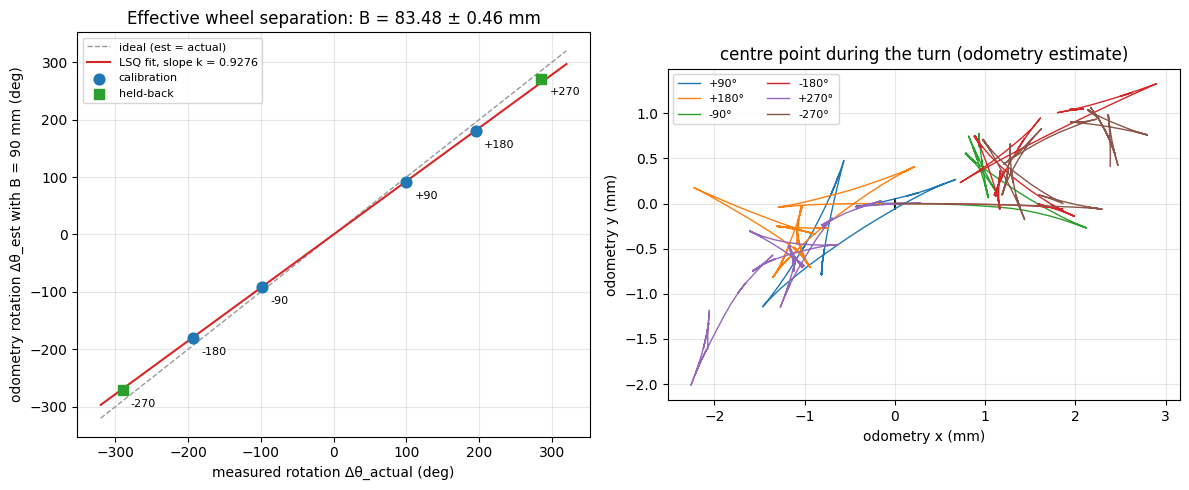

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
lim = 320
line = np.linspace(-lim, lim, 10)
ax[0].plot(line, line, color="0.6", lw=1, ls="--", label="ideal (est = actual)")
ax[0].plot(line, k * line, color="C3", lw=1.5, label=f"LSQ fit, slope k = {k:.4f}")
for role, mk, col in [("calibration", "o", "C0"), ("held-back", "s", "C2")]:
    s = measured[measured.role == role]
    ax[0].scatter(s.measured_deg, s.est_deg, marker=mk, s=60, color=col, label=role, zorder=3)
    for _, r in s.iterrows():
        ax[0].annotate(f"{r.commanded_deg:+.0f}", (r.measured_deg, r.est_deg),
                       textcoords="offset points", xytext=(6, -12), fontsize=8)
ax[0].set_xlabel("measured rotation Δθ_actual (deg)")
ax[0].set_ylabel("odometry rotation Δθ_est with B = 90 mm (deg)")
ax[0].set_title(f"Effective wheel separation: B = {B_fit:.2f} ± {B_se:.2f} mm")
ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)

for f, lg in logs.items():
    row = trials[trials.file == f].iloc[0]
    if pd.isna(row.measured_deg):
        continue
    ax[1].plot(lg.odometry_x_mm, lg.odometry_y_mm, lw=1, label=f"{row.commanded_deg:+.0f}°")
ax[1].scatter([0], [0], color="k", marker="+", s=80)
ax[1].set_aspect("equal"); ax[1].grid(alpha=0.3)
ax[1].set_xlabel("odometry x (mm)"); ax[1].set_ylabel("odometry y (mm)")
ax[1].set_title("centre point during the turn (odometry estimate)")
ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
os.makedirs(f"{BASE}/analysis", exist_ok=True)
plt.savefig(f"{BASE}/analysis/rotation_fit.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. 敏感性：手写读数的影响

In [7]:
# How much does a misread angle move B? Example: the +180 reading (confirmed 195) taken as 185.
alt = cal.copy()
alt.loc[alt.commanded_deg == 180, "measured_deg"] = 185
a2 = np.radians(alt.measured_deg.values); e2 = np.radians(alt.est_deg.values)
k2 = float(np.sum(a2 * e2) / np.sum(a2 * a2))
print(f"+180 read as 195: B = {B_fit:.2f} mm (single-trial +180 B = "
      f"{float(B_OLD_MM * cal[cal.commanded_deg == 180].est_deg.iloc[0] / 195):.2f} mm)")
print(f"+180 read as 185: B = {B_OLD_MM * k2:.2f} mm (single-trial +180 B = "
      f"{float(B_OLD_MM * cal[cal.commanded_deg == 180].est_deg.iloc[0] / 185):.2f} mm)")
print("each 1° reading error on a 90° turn moves that trial's B by about "
      f"{B_OLD_MM * 90.6 / 100 - B_OLD_MM * 90.6 / 101:.2f} mm; on a 180° turn by about "
      f"{B_OLD_MM * 180.4 / 193 - B_OLD_MM * 180.4 / 194:.2f} mm")

+180 read as 195: B = 83.48 mm (single-trial +180 B = 83.20 mm)
+180 read as 185: B = 85.18 mm (single-trial +180 B = 87.70 mm)
each 1° reading error on a 90° turn moves that trial's B by about 0.81 mm; on a 180° turn by about 0.43 mm


## 7. 结论

- 小车每次都**转多了**（实际比里程计多转 5–10%），说明模型里的 B = 90 mm 偏大；有效轮距约 **83.5 mm**。
- 顺时针三次的单次 B 非常一致（84.0、84.2、84.0 mm）；逆时针三次比较分散（81.5、83.2、85.6 mm），
  平均值接近，没有明显的方向依赖。+90° 那次偏差最大，而 90° 的单次读数误差影响也最大（每 1° 约 0.8 mm）。
- 用拟合的 B 修正后，留作检验的 ±270° 航向误差明显减小。
- 这是**有效**轮距：它依赖于 r = 16.36 mm、这块地面、停车时的滑行和测量方法，不等于用尺子量的轮间距。
- 不足：每个角度目前只有 1 次实际测量（课程要求每个条件 ≥ 5 次），不确定度是用 4 个标定点估计的，偏乐观。
  第 6 节给出读数误差的敏感性（+180° 读数已确认为 195°）。